In [1]:
import yfinance as yf
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt

In [2]:
apple = yf.download(tickers='AAPL', start='2021-04-06',end='2023-04-06',rounding=True)
apple

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-04-06,122.71,123.60,122.16,122.99,80171300
2021-04-07,124.35,124.37,121.67,122.34,83466700
2021-04-08,126.74,126.77,124.95,125.37,88844600
2021-04-09,129.31,129.35,125.88,126.20,106686700
2021-04-12,127.60,129.16,127.01,128.84,91420000
...,...,...,...,...,...
2023-03-30,159.76,159.86,158.68,158.94,49501700
2023-03-31,162.26,162.35,159.31,159.84,68749800


In [3]:
apple = apple["Close"]
apple

Ticker,AAPL
Date,
2021-04-06,122.71
2021-04-07,124.35
2021-04-08,126.74
2021-04-09,129.31
2021-04-12,127.60
...,...
2023-03-30,159.76
2023-03-31,162.26
2023-04-03,163.51


In [4]:
apple.index = pd.to_datetime(apple.index)
len_train = int(len(apple)*0.8)
len_train

404

In [5]:
len_train = int(len(apple)*0.2)
len_train

101

In [6]:
train=apple[0:len_train]
train

Ticker,AAPL
Date,
2021-04-06,122.71
2021-04-07,124.35
2021-04-08,126.74
2021-04-09,129.31
2021-04-12,127.60
...,...
2021-08-20,144.54
2021-08-23,146.02
2021-08-24,145.93


In [7]:
test=apple[len_train:]
test

Ticker,AAPL
Date,
2021-08-27,144.94
2021-08-30,149.35
2021-08-31,148.09
2021-09-01,148.75
2021-09-02,149.87
...,...
2023-03-30,159.76
2023-03-31,162.26
2023-04-03,163.51


[1.         0.97508838 0.95095817 0.92998719 0.91108582 0.8924837
 0.87144822 0.84946122 0.82769371 0.80831373 0.78820593 0.77008198
 0.74822488 0.72726577 0.70637474 0.68485907 0.66539616 0.64629724
 0.62882285 0.60855727 0.58791293 0.5665603  0.54469788 0.52500462
 0.50510206 0.48515899 0.46523687 0.4454992 ]


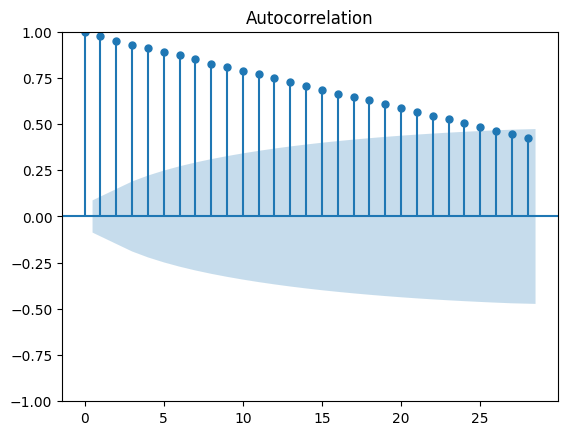

In [8]:
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf
acf_array = acf(apple)
print(acf_array)
plot_acf(apple,alpha=0.05)
plt.show()

In [9]:
from statsmodels.tsa.arima.model import ARIMA

mod= ARIMA(train, order=(1,0,0))
res=mod.fit()

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


In [10]:
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                  101
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -197.804
Date:                Thu, 15 Oct 2026   AIC                            401.608
Time:                        12:29:50   BIC                            409.454
Sample:                             0   HQIC                           404.784
                                - 101                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        133.0563      6.694     19.878      0.000     119.937     146.176
ar.L1          0.9839      0.020     48.720      0.000       0.944       1.023
sigma2         2.8432      0.429      6.627      0.0

In [11]:
predicciones= res.forecast(len(test))
predicciones

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


101    143.734968
102    143.562760
103    143.393328
104    143.226628
105    143.062617
          ...    
500    133.072523
501    133.072261
502    133.072003
503    133.071749
504    133.071499
Name: predicted_mean, Length: 404, dtype: float64

In [12]:
conf = res.get_forecast(len(test)).conf_int(alpha=0.05)
conf

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


,lower AAPL,upper AAPL
101,140.430092,147.039845
102,138.926491,148.199028
103,137.760432,149.026223
104,136.773985,149.679271
105,135.905331,150.219903
...,...,...
500,114.595614,151.549433
501,114.595351,151.549171
502,114.595092,151.548914
503,114.594838,151.548660


In [13]:
fcast_res = res.get_forecast(len(test))
print(fcast_res.summary_frame(alpha=0.05))

AAPL        mean   mean_se  mean_ci_lower  mean_ci_upper
101   143.734968  1.686192     140.430092     147.039845
102   143.562760  2.365487     138.926491     148.199028
103   143.393328  2.873979     137.760432     149.026223
104   143.226628  3.292225     136.773985     149.679271
105   143.062617  3.651744     135.905331     150.219903
..           ...       ...            ...            ...
500   133.072523  9.427168     114.595614     151.549433
501   133.072261  9.427168     114.595351     151.549171
502   133.072003  9.427168     114.595092     151.548914
503   133.071749  9.427169     114.594838     151.548660
504   133.071499  9.427169     114.594587     151.548411

[404 rows x 4 columns]


D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


In [14]:
test=pd.DataFrame(test)
predicciones= pd.DataFrame(predicciones)
test=test.reset_index()
predicciones= predicciones.reset_index()

In [15]:
predicciones

,index,predicted_mean
0,101,143.734968
1,102,143.562760
2,103,143.393328
3,104,143.226628
4,105,143.062617
...,...,...
399,500,133.072523
400,501,133.072261
401,502,133.072003
402,503,133.071749


In [16]:
test

Ticker,Date,AAPL
0,2021-08-27,144.94
1,2021-08-30,149.35
2,2021-08-31,148.09
3,2021-09-01,148.75
4,2021-09-02,149.87
...,...,...
399,2023-03-30,159.76
400,2023-03-31,162.26
401,2023-04-03,163.51
402,2023-04-04,162.97


In [17]:
import numpy as np

acumulador1 = 0
acumulador2 = 0

for contador in range(0, 101):
    acumulador1 += (test.iloc[contador][1] - predicciones.iloc[contador][1])**2
    acumulador2 += (np.abs(test.iloc[contador][1] - predicciones.iloc[contador][1])/ test.iloc[contador][1])

mse = acumulador1 / 101
rmse = np.round(np.sqrt(mse), 2)
mape = np.round((acumulador2 / 101) * 100, 2)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MSE: 450.4611753102554
RMSE: 21.22
MAPE: 9.82 %


In [18]:
predicciones= res.forecast(len(test)+5)
predicciones.tail(5)

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


505    133.071253
506    133.071012
507    133.070774
508    133.070539
509    133.070309
Name: predicted_mean, dtype: float64

In [19]:
conf = res.get_forecast(len(test)+5).conf_int(alpha=0.05)
conf.tail(5)

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


,lower AAPL,upper AAPL
505,114.594341,151.548166
506,114.594099,151.547924
507,114.593860,151.547687
508,114.593625,151.547454
509,114.593395,151.547224


In [20]:
train=pd.DataFrame(train)
lista=test["Date"]
lista=pd.DataFrame(lista)
test.index=test["Date"]
test.drop(columns=["Date"],inplace=True)
test

Ticker,AAPL
Date,
2021-08-27,144.94
2021-08-30,149.35
2021-08-31,148.09
2021-09-01,148.75
2021-09-02,149.87
...,...
2023-03-30,159.76
2023-03-31,162.26
2023-04-03,163.51


In [21]:
lista

,Date
0,2021-08-27
1,2021-08-30
2,2021-08-31
3,2021-09-01
4,2021-09-02
...,...
399,2023-03-30
400,2023-03-31
401,2023-04-03
402,2023-04-04


In [22]:
import pandas as pd

k = 5
lista2 = []

for day in range(1, k + 1):
    fecha = (pd.to_datetime("2023-04-05") + pd.offsets.BDay(day)).date()
    lista2.append(fecha)

lista2 = pd.DataFrame(lista2, columns=["Date"])
lista2["Date"] = pd.to_datetime(lista2["Date"])

# Concatenar ambos DataFrames
fecha = pd.concat([lista, lista2], ignore_index=True)

fecha

,Date
0,2021-08-27
1,2021-08-30
2,2021-08-31
3,2021-09-01
4,2021-09-02
...,...
404,2023-04-06
405,2023-04-07
406,2023-04-10
407,2023-04-11


In [23]:
fecha = pd.concat([lista, lista2])
fecha = fecha.reset_index(drop=True)
fecha

,Date
0,2021-08-27
1,2021-08-30
2,2021-08-31
3,2021-09-01
4,2021-09-02
...,...
404,2023-04-06
405,2023-04-07
406,2023-04-10
407,2023-04-11


In [24]:
fecha.columns

Index(['Date'], dtype='object')

In [25]:
predicciones = pd.DataFrame(predicciones)
predicciones = predicciones.reset_index()
predicciones

,index,predicted_mean
0,101,143.734968
1,102,143.562760
2,103,143.393328
3,104,143.226628
4,105,143.062617
...,...,...
404,505,133.071253
405,506,133.071012
406,507,133.070774
407,508,133.070539


In [26]:
predicciones.drop(columns=["index"], inplace=True)
predicciones

,predicted_mean
0,143.734968
1,143.562760
2,143.393328
3,143.226628
4,143.062617
...,...
404,133.071253
405,133.071012
406,133.070774
407,133.070539


In [27]:
frames = [fecha, predicciones]
result = pd.concat(frames, axis=1, join='inner')
result.columns = ['Date', 'Predicciones']
result

,Date,Predicciones
0,2021-08-27,143.734968
1,2021-08-30,143.562760
2,2021-08-31,143.393328
3,2021-09-01,143.226628
4,2021-09-02,143.062617
...,...,...
404,2023-04-06,133.071253
405,2023-04-07,133.071012
406,2023-04-10,133.070774
407,2023-04-11,133.070539


In [28]:
print(result.dtypes)

Date            datetime64[ns]
Predicciones           float64
dtype: object


In [29]:
result.index = result['Date']
result.drop(columns=["Date"], inplace=True)
result

,Predicciones
Date,
2021-08-27,143.734968
2021-08-30,143.562760
2021-08-31,143.393328
2021-09-01,143.226628
2021-09-02,143.062617
...,...
2023-04-06,133.071253
2023-04-07,133.071012
2023-04-10,133.070774


In [30]:
conf = conf.reset_index()
conf.drop(columns=["index"], inplace=True)
conf

,lower AAPL,upper AAPL
0,140.430092,147.039845
1,138.926491,148.199028
2,137.760432,149.026223
3,136.773985,149.679271
4,135.905331,150.219903
...,...,...
404,114.594341,151.548166
405,114.594099,151.547924
406,114.593860,151.547687
407,114.593625,151.547454


In [31]:
frames = [fecha, conf]
intervalos = pd.concat(frames, axis=1, join='inner')
intervalos

,Date,lower AAPL,upper AAPL
0,2021-08-27,140.430092,147.039845
1,2021-08-30,138.926491,148.199028
2,2021-08-31,137.760432,149.026223
3,2021-09-01,136.773985,149.679271
4,2021-09-02,135.905331,150.219903
...,...,...,...
404,2023-04-06,114.594341,151.548166
405,2023-04-07,114.594099,151.547924
406,2023-04-10,114.593860,151.547687
407,2023-04-11,114.593625,151.547454


In [32]:
intervalos.index = intervalos['Date']
intervalos.drop(columns=["Date"], inplace=True)
intervalos

,lower AAPL,upper AAPL
Date,,
2021-08-27,140.430092,147.039845
2021-08-30,138.926491,148.199028
2021-08-31,137.760432,149.026223
2021-09-01,136.773985,149.679271
2021-09-02,135.905331,150.219903
...,...,...
2023-04-06,114.594341,151.548166
2023-04-07,114.594099,151.547924
2023-04-10,114.593860,151.547687


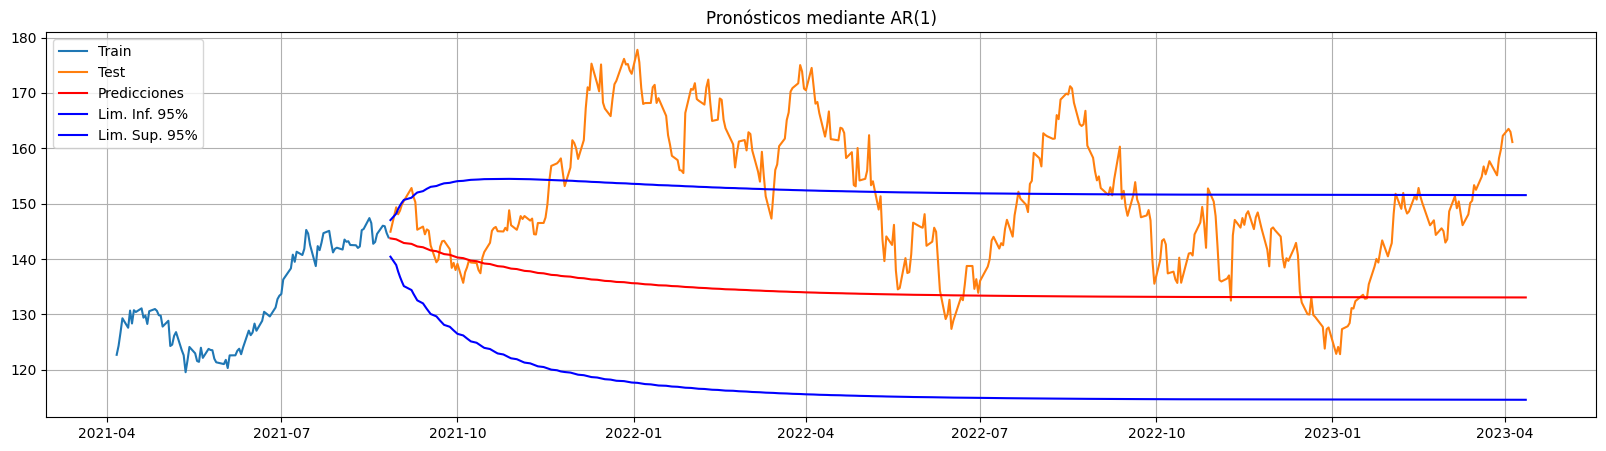

In [33]:
plt.figure(figsize=(20,5))
plt.grid()
plt.plot(train, label="Train")
plt.plot(test, label="Test")
plt.plot(result, label="Predicciones", color="red")
plt.plot(intervalos['lower AAPL'], label="Lim. Inf. 95%", color="blue")
plt.plot(intervalos['upper AAPL'], label="Lim. Sup. 95%", color="blue")
plt.legend(loc="best")
plt.title("Pronósticos mediante AR(1)")
plt.show()

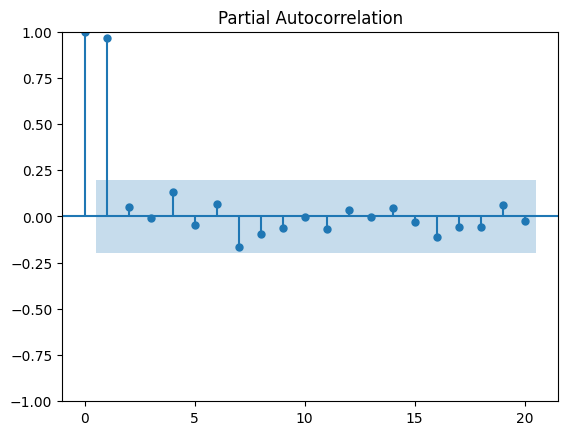

In [34]:
# Determinación del valor adecuado de p para AR(p) a partir de la función de Autoco...
from statsmodels.graphics.tsaplots import plot_pacf
plot_pacf(train, lags=20)
plt.show()

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\stats

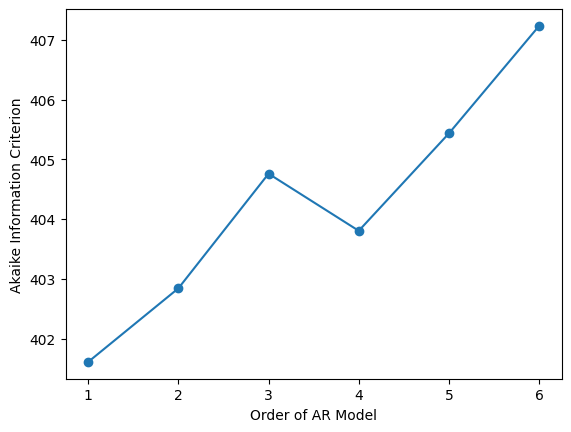

In [35]:
# Determinación del valor adecuado de p para AR(p) a partir del criterio de informac...
# Fit the data to an AR(p) for p = 0,...,6 , and save the BIC
AIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(train, order=(p,0,0))
    res = mod.fit()
# Save BIC for AR(p)
    AIC[p] = res.aic

# Plot the BIC as a function of p
plt.plot(range(1,7), AIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Akaike Information Criterion')
plt.show()

D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
D:\anaconda3\Lib\site-packages\stats

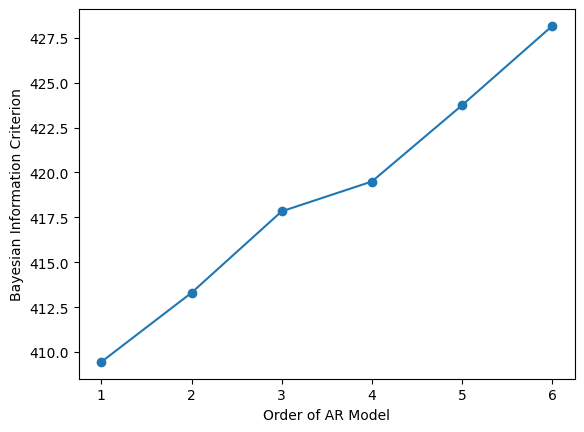

In [36]:
# Determinación del valor adecuado de p para AR(p) a partir del criterio de información
# Fit the data to an AR(p) for p = 0,...,6 , and save the BIC
BIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(train, order=(p,0,0))
    res = mod.fit()
# Save BIC for AR(p)
    BIC[p] = res.bic

# Plot the BIC as a function of p
plt.plot(range(1,7), BIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Bayesian Information Criterion')
plt.show()